# Session 5 · Tuning the selected CNN

I kept the three-block CNN with batch normalization. I wanted to know how much I could gain by changing what each image looked like during training, so I tested flips and brightness separately before putting them together.

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
artifacts = Path("Artifacts")
manifest_path = artifacts / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)
classes = sorted(manifest.loc[manifest.split == "train", "label"].unique().tolist())
class_ids = list(range(len(classes)))
label_id = {name: i for i, name in enumerate(classes)}
assert len(classes) == 6
train_rows = manifest.loc[manifest.split == "train"].reset_index(drop=True)
val_rows = manifest.loc[manifest.split == "validation"].reset_index(drop=True)
assert train_rows.label.value_counts().reindex(classes).eq(210).all()
assert val_rows.label.value_counts().reindex(classes).eq(45).all()
assert set(train_rows.pixel_sha256).isdisjoint(val_rows.pixel_sha256)
print(f"{len(train_rows)} training images, {len(val_rows)} validation images. Running on CPU.")

manifest_digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
control_saved = torch.load(artifacts / "deep_cnn_bn.pt", map_location="cpu", weights_only=True)
control = json.loads((artifacts / "deep_cnn_bn_validation.json").read_text(encoding="utf-8"))
for previous in (control, control_saved):
    assert previous["classes"] == classes and previous["manifest_sha256"] == manifest_digest
assert control["validation_macro_f1"] == control_saved["validation_macro_f1"]

1260 training images, 270 validation images. Running on CPU.


In [2]:
def load_images(rows):
    pixels = torch.empty((len(rows), 1, 200, 200), dtype=torch.uint8)
    for index, row in enumerate(rows.itertuples(index=False)):
        with Image.open(row.path) as image:
            if image.size != (200, 200) or image.mode != "L":
                raise ValueError(f"Unexpected image format: {row.path}")
            if hashlib.sha256(image.tobytes()).hexdigest() != row.pixel_sha256:
                raise ValueError(f"Pixel content changed since Session 1: {row.path}")
            pixels[index, 0] = torch.from_numpy(np.array(image))
    targets = torch.tensor(rows.label.map(label_id).tolist(), dtype=torch.long)
    return TensorDataset(pixels, targets)

train_data = load_images(train_rows)
val_data = load_images(val_rows)
mean, std = control_saved["mean"], control_saved["std"]

def normalize(pixels):
    return (pixels.float() / 255.0 - mean) / std

batch_size = 64
val_loader = DataLoader(val_data, batch_size=batch_size)
print(f"Training mean {mean:.4f}, standard deviation {std:.4f} on a 0–1 scale.")

Training mean 0.5009, standard deviation 0.2125 on a 0–1 scale.


## Checking what the augmentations do to the defect

A horizontal flip moves a scratch to the other side of the crop while preserving its label. I also tried multiplying brightness by a value between 0.9 and 1.1. The gallery shows both extremes on one example per class. In the training loop each image had its own brightness draw and a 50% flip probability when those settings were enabled. Validation always used the original crops.

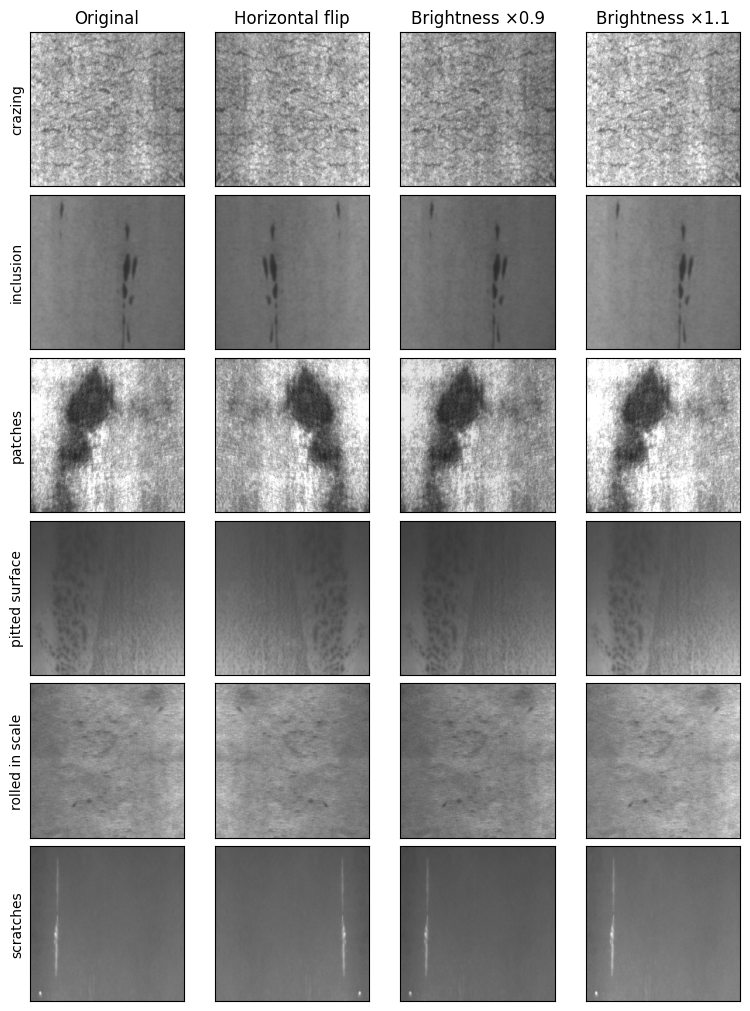

In [3]:
def change_brightness(pixels, factor):
    return (pixels.float() * factor).clamp(0, 255)

def augment(pixels, flips, brightness, flip_rng, brightness_rng):
    draw_shape = (len(pixels), 1, 1, 1)
    if flips:
        mask = torch.rand(draw_shape, generator=flip_rng) < 0.5
        pixels = torch.where(mask, pixels.flip(-1), pixels)
    if brightness:
        factors = 0.9 + 0.2 * torch.rand(draw_shape, generator=brightness_rng)
        pixels = change_brightness(pixels, factors)
    return pixels

fig, axes = plt.subplots(len(classes), 4, figsize=(7.5, 10), layout="constrained")
for row, label in enumerate(classes):
    idx = train_rows.index[train_rows.label == label][0]
    image = train_data.tensors[0][idx, 0]
    variants = [image, image.flip(-1), change_brightness(image, 0.9), change_brightness(image, 1.1)]
    for col, variant in enumerate(variants):
        ax = axes[row, col]
        ax.imshow(variant, cmap="gray", vmin=0, vmax=255)
        ax.set(xticks=[], yticks=[])
        if row == 0:
            ax.set_title(["Original", "Horizontal flip", "Brightness ×0.9", "Brightness ×1.1"][col])
    axes[row, 0].set_ylabel(label.replace("_", " "))
plt.show()

## Comparing each change with the control

I first reproduced Session 4’s validation confusion matrix. Then I trained each variant with the same starting weights, minibatch order and 20-epoch budget. I used separate random generators for flips and brightness so the same decisions were available in the single and combined runs.

In [4]:
def make_deep_cnn(batch_norm):
    layers = []
    for inputs, outputs, kernel, stride in [(1, 8, 5, 2), (8, 16, 3, 1), (16, 16, 3, 1)]:
        layers.append(nn.Conv2d(inputs, outputs, kernel, stride, padding=kernel // 2))
        if batch_norm:
            layers.append(nn.BatchNorm2d(outputs))
        layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
    layers.extend([nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, len(classes))])
    return nn.Sequential(*layers).to(memory_format=torch.channels_last)

epochs = 20
reference_lr = control['learning_rate']
loss_fn = nn.CrossEntropyLoss()

@torch.inference_mode()
def validate(network):
    network.eval()
    outputs = torch.cat([network(normalize(x)) for x, _ in val_loader])
    targets = val_data.tensors[1]
    predictions = outputs.argmax(dim=1)
    score = f1_score(targets.numpy(), predictions.numpy(), labels=class_ids,
                     average="macro", zero_division=0)
    return loss_fn(outputs, targets).item(), float(score), predictions

def run_experiment(name, flips, brightness, learning_rate):
    torch.manual_seed(seed)
    model = make_deep_cnn(True)
    flip_rng = torch.Generator().manual_seed(seed + 1)
    brightness_rng = torch.Generator().manual_seed(seed + 2)
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_score = -1.0
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for pixels, targets in loader:
            optimizer.zero_grad(set_to_none=True)
            inputs = augment(pixels, flips, brightness, flip_rng, brightness_rng)
            loss = loss_fn(model(normalize(inputs)), targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(targets)
        val_loss, score, predictions = validate(model)
        history.append({"epoch": epoch, "train_loss": total_loss / len(train_data),
                        "validation_loss": val_loss, "validation_macro_f1": score})
        if score > best_score:
            best_epoch, best_score = epoch, score
            best_state = deepcopy(model.state_dict())
            best_predictions = predictions.clone()
        if epoch == 1 or epoch % 5 == 0:
            print(f"{name}, epoch {epoch:2d}: validation macro F1 {score:.4f}")

    checkpoint = artifacts / f"{name}.pt"
    payload = {"state_dict": best_state, "architecture": "deep_cnn_bn", "batch_norm": True,
               "flips": flips, "brightness": brightness, "learning_rate": learning_rate,
               "channels": [8, 16, 16], "classes": classes, "input_shape": [1, 200, 200],
               "mean": mean, "std": std, "seed": seed, "epoch": best_epoch,
               "validation_macro_f1": best_score, "manifest_sha256": manifest_digest}
    temporary = checkpoint.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(checkpoint)
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    restored = make_deep_cnn(saved["batch_norm"])
    restored.load_state_dict(saved["state_dict"])
    _, score, predicted = validate(restored)
    assert torch.equal(predicted, best_predictions) and score == best_score
    actual = val_data.tensors[1].numpy()
    report = classification_report(actual, predicted.numpy(), labels=class_ids,
                                   target_names=classes, output_dict=True, zero_division=0)
    metrics = {"model": name, "parameters": sum(p.numel() for p in restored.parameters()),
               "batch_norm": True, "flips": flips, "brightness": brightness, "learning_rate": learning_rate, "batch_size": batch_size,
               "seed": seed, "best_epoch": best_epoch, "validation_macro_f1": score,
               "classes": classes, "validation_report": report, "history": history,
               "validation_confusion_matrix": confusion_matrix(actual, predicted, labels=class_ids).tolist(),
               "manifest_sha256": manifest_digest}
    (artifacts / f"{name}_validation.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    return metrics

In [5]:
control_model = make_deep_cnn(True)
control_model.load_state_dict(control_saved["state_dict"])
actual = val_data.tensors[1].numpy()
_, control_score, control_predictions = validate(control_model)
assert control_score == control["validation_macro_f1"]
assert confusion_matrix(actual, control_predictions, labels=class_ids).tolist() == control["validation_confusion_matrix"]
runs = {"deep_cnn_bn": control}
print(f"Reproduced control macro F1: {control_score:.4f}")

Reproduced control macro F1: 0.9408


In [6]:
runs["cnn_flips"] = run_experiment("cnn_flips", True, False, reference_lr)

cnn_flips, epoch  1: validation macro F1 0.1029


cnn_flips, epoch  5: validation macro F1 0.8099


cnn_flips, epoch 10: validation macro F1 0.8750


cnn_flips, epoch 15: validation macro F1 0.9188


cnn_flips, epoch 20: validation macro F1 0.9336


In [7]:
runs["cnn_brightness"] = run_experiment("cnn_brightness", False, True, reference_lr)

cnn_brightness, epoch  1: validation macro F1 0.1036


cnn_brightness, epoch  5: validation macro F1 0.8248


cnn_brightness, epoch 10: validation macro F1 0.8753


cnn_brightness, epoch 15: validation macro F1 0.9264


cnn_brightness, epoch 20: validation macro F1 0.9335


In [8]:
runs["cnn_flips_brightness"] = run_experiment("cnn_flips_brightness", True, True, reference_lr)

cnn_flips_brightness, epoch  1: validation macro F1 0.1029


cnn_flips_brightness, epoch  5: validation macro F1 0.8178


cnn_flips_brightness, epoch 10: validation macro F1 0.8751


cnn_flips_brightness, epoch 15: validation macro F1 0.9122


cnn_flips_brightness, epoch 20: validation macro F1 0.9301


## Doubling the learning rate

At 0.0003, flips alone and brightness alone each got 255 of 270 validation images right. Combining them got 256. I kept that combination and tried Adam at 0.0006 under the same epoch budget. The original runs stayed eligible for selection.

In [9]:
best_policy = max(runs, key=lambda key: runs[key]["validation_macro_f1"])
policy = runs[best_policy]
print(f"Learning-rate comparison uses the augmentation policy from {best_policy}.")
runs["cnn_double_lr"] = run_experiment("cnn_double_lr", policy.get("flips", False),
                                      policy.get("brightness", False), reference_lr * 2)

Learning-rate comparison uses the augmentation policy from cnn_flips_brightness.


cnn_double_lr, epoch  1: validation macro F1 0.1567


cnn_double_lr, epoch  5: validation macro F1 0.8820


cnn_double_lr, epoch 10: validation macro F1 0.8822


cnn_double_lr, epoch 15: validation macro F1 0.9523


cnn_double_lr, epoch 20: validation macro F1 0.9668


## Which predictions actually changed

The faster learning rate reached 265 correct, including 44 of 45 scratches. I compared individual predictions with the unaugmented control. The selected model corrected 14 earlier mistakes and lost three previously correct cases. That accounts for the net gain of 11.

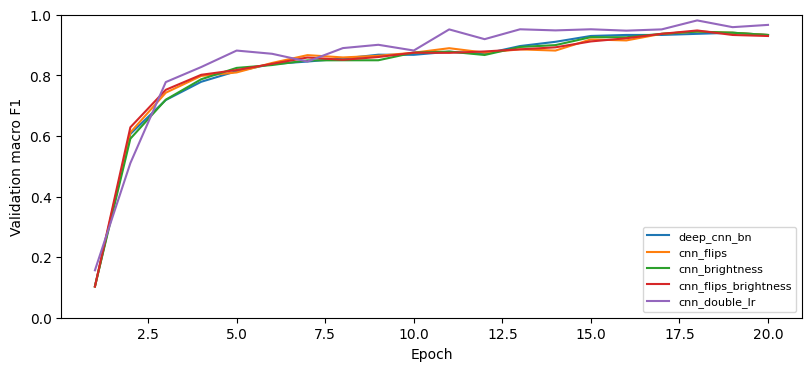

,learning rate,epoch,macro F1,correct / 270,scratches / 45
run,,,,,
deep_cnn_bn,0.0003,19,0.9408,254,39
cnn_flips,0.0003,18,0.9447,255,40
cnn_brightness,0.0003,18,0.9447,255,40
cnn_flips_brightness,0.0003,18,0.9484,256,40
cnn_double_lr,0.0006,18,0.9816,265,44


Predicted,crazing,inclusion,patches,pitted_surface,rolled_in_scale,scratches
Actual,,,,,,
crazing,44,0,1,0,0,0
inclusion,0,45,0,0,0,0
patches,0,0,45,0,0,0
pitted_surface,0,3,0,42,0,0
rolled_in_scale,0,0,0,0,45,0
scratches,0,1,0,0,0,44


cnn_double_lr: 14 formerly incorrect predictions corrected, 3 formerly correct predictions lost.
Remaining scratch errors: {'inclusion': 1}


WindowsPath('Artifacts/session5_selection.json')

In [10]:
selected = max(runs, key=lambda key: runs[key]["validation_macro_f1"])
summary = []
scratch_id = label_id["scratches"]
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
for key, result in runs.items():
    matrix = np.asarray(result["validation_confusion_matrix"])
    assert matrix.shape == (6, 6) and matrix.sum() == 270
    summary.append({"run": key, "learning rate": result["learning_rate"], "epoch": result["best_epoch"],
                    "macro F1": result["validation_macro_f1"], "correct / 270": int(matrix.trace()),
                    "scratches / 45": int(matrix[scratch_id, scratch_id])})
    history = pd.DataFrame(result["history"])
    ax.plot(history.epoch, history.validation_macro_f1, label=key)
ax.set(xlabel="Epoch", ylabel="Validation macro F1", ylim=(0, 1))
ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(summary).set_index("run").round(4))

saved = torch.load(artifacts / f"{selected}.pt", map_location="cpu", weights_only=True)
assert saved["manifest_sha256"] == manifest_digest and saved["classes"] == classes
winner = make_deep_cnn(True)
winner.load_state_dict(saved["state_dict"])
_, score, predictions = validate(winner)
assert score == runs[selected]["validation_macro_f1"]
matrix = confusion_matrix(actual, predictions, labels=class_ids)
assert matrix.tolist() == runs[selected]["validation_confusion_matrix"]
display(pd.DataFrame(matrix, index=pd.Index(classes, name="Actual"), columns=pd.Index(classes, name="Predicted")))
control_correct = control_predictions.numpy() == actual
winner_correct = predictions.numpy() == actual
gained = int((~control_correct & winner_correct).sum())
lost = int((control_correct & ~winner_correct).sum())
print(f"{selected}: {gained} formerly incorrect predictions corrected, {lost} formerly correct predictions lost.")
print("Remaining scratch errors:", {name: int(matrix[scratch_id, i]) for i, name in enumerate(classes)
                                    if i != scratch_id and matrix[scratch_id, i]})

selection = {"selected_checkpoint": f"{selected}.pt", "selected_report": f"{selected}_validation.json",
             "checkpoint_sha256": hashlib.sha256((artifacts / f"{selected}.pt").read_bytes()).hexdigest(),
             "manifest_sha256": manifest_digest, "best_augmentation_run": best_policy,
             "selection_metric": "validation_macro_f1", "validation_macro_f1": score,
             "classes": classes, "corrected_vs_control": gained, "lost_vs_control": lost,
             "comparisons": summary}
target = artifacts / "session5_selection.json"
temporary = target.with_suffix(".tmp")
temporary.write_text(json.dumps(selection, indent=2), encoding="utf-8")
temporary.replace(target)

## My final training choice

I selected epoch 18 of the combined augmentation run at 0.0006. It scored 0.9816 validation macro F1. Most of the gain in this session came from the learning-rate comparison at the same augmentation setting. I used one seed and one validation split, so I treat that as a finding about this run. I saved the checkpoint identity before opening the test images.